[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch56_LabCh56_Two_Tower_Recommender.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 56: Tables and Recommenders** (Part XII: Other Shapes of Data).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=56](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=56)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch56 - A table, then a two-tower recommender
## Lose to a tree on a spreadsheet, then win where a column has thousands of values

This lab goes with **Chapter 56** of *The Why Book of Deep Learning, Part 2*.

You run a small film service. This notebook invents its whole history from a formula: 3,000 users with
hidden **tastes**, 600 films with hidden **traits**, and about 120,000 viewings with a star rating each.
Because the notebook made the world, it knows the truth, and every model can be marked against it.

| Part | Question | Models | Score |
|---|---|---|---|
| One: a table | How many stars will this user give this film? | means, a linear model, gradient-boosted trees, an MLP with embedding columns | RMSE in stars (lower is better) |
| Two: retrieval | Which 10 of 560 films should this user see next? | most popular, a two-tower model with in-batch negatives | recall@10 on held-out viewings (higher is better) |

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Generate interactions with a known truth, a popularity skew and noise | Steps 2 and 3 |
| Split interactions by time and prove that nothing leaks | Step 4 |
| Build the baselines that every table model must beat, and the floor nobody can beat | Steps 5 and 6 |
| Feed a table to a network properly: scaled numbers, embedded categories, a hand-checked parameter count | Steps 8 and 9 |
| Say what an id embedding buys that a tree cannot get from the id | Steps 9 and 10 |
| Write the in-batch-negatives loss, and correct its bias against popular items | Steps 12 to 14 |
| Measure recall@10 fairly, and show how much three common mistakes distort it | Steps 11 and 15 |
| Compare learnt item vectors with the hidden traits | Step 16 |
| Show the cold-start failure for new films and repair it with item features | Steps 17 and 18 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **Runtime:** one to two minutes on a laptop CPU. No GPU and no downloads: all the data is made here.

> **The one optional extra:** Step 7 uses a gradient-boosted tree model from **scikit-learn** if it is
> installed. Everything else needs only NumPy, Matplotlib and TensorFlow / Keras. Without scikit-learn the
> notebook still runs from top to bottom: the tree rows are skipped and say so.

> **Honest scale:** this is a miniature. A real service has millions of users and items, a matrix far
> emptier than ours, tastes that drift, and feedback that the recommender itself has shaped. The numbers
> printed here compare the models in this notebook with each other. They are not what a production system
> scores.

---
## Step 1 - Imports and one seed

In [1]:
import os, time
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

try:                                             # the one optional extra
    from sklearn.ensemble import HistGradientBoostingRegressor
    HAVE_SKLEARN = True
except Exception:
    HAVE_SKLEARN = False

SEED = 56
keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=3, suppress=True, linewidth=120)
t_start = time.time()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| scikit-learn available:", HAVE_SKLEARN)

TensorFlow 2.21.0 | Keras 3.14.1 | scikit-learn available: True


---
## Step 2 - The hidden world: tastes and traits

Every user gets a hidden **taste** vector of 4 numbers and every film a hidden **trait** vector of 4 numbers.
How much a user is drawn to a film is the **dot product** of the two (Chapter 18 drew this picture). Nobody
in the notebook's "company" can see these vectors. They see only the ordinary columns:

| Who | Visible columns | What they hide |
|---|---|---|
| user | `age`, `region` (10 values), `plan` (3 values) | region shifts the taste; age follows taste 0; plan follows generosity |
| film | `genre` (8 values), `year`, `budget` (dollars), `length` (minutes) | genre sets most of the traits; year and budget follow quality; length follows trait 1; big budgets make films better known |

So the visible columns explain **part** of the tastes and traits, and the rest is individual. The last 40
films are **new releases**: they come out after all the training data was collected (Step 17).

> **Predict:** `budget` is drawn on a log scale around e^16 dollars (about 9 million). Roughly how many times
> larger is the biggest budget than the median? Remember your answer when a network meets this column in Step 8.

In [2]:
N_USERS, N_ITEMS, K = 3000, 600, 4
N_NEW = 40                                   # films released after the training data ends
N_OLD = N_ITEMS - N_NEW                      # the catalogue: 560 films
REGIONS, PLANS, DEVICES = 10, 3, 4
GENRES = ["action", "comedy", "drama", "horror", "romance", "sci-fi", "documentary", "animation"]

# users
region = rng.integers(0, REGIONS, N_USERS)
region_centre = rng.normal(0, 1, (REGIONS, K))
taste = 0.6 * region_centre[region] + 0.8 * rng.normal(0, 1, (N_USERS, K))      # HIDDEN
plan = rng.choice(PLANS, N_USERS, p=[0.6, 0.3, 0.1])
age = np.clip(38 - 7 * taste[:, 0] + rng.normal(0, 8, N_USERS), 16, 80).round()
generous = 0.25 * (plan - 0.5) + rng.normal(0, 0.35, N_USERS)                   # HIDDEN: easy or hard marker

# films
genre = rng.integers(0, len(GENRES), N_ITEMS)
genre_centre = rng.normal(0, 1, (len(GENRES), K))
trait = 0.8 * genre_centre[genre] + 0.6 * rng.normal(0, 1, (N_ITEMS, K))        # HIDDEN
quality = rng.normal(0, 0.45, N_ITEMS)                                          # HIDDEN
q_std = quality / 0.45
year = np.clip(2010 + 4 * q_std + rng.normal(0, 6, N_ITEMS), 1980, 2025).round()
money = rng.normal(0, 1, N_ITEMS)
budget = np.exp(16 + 1.2 * money + 0.5 * q_std)                                 # dollars, heavy tail
length = np.clip(105 + 14 * trait[:, 1] + rng.normal(0, 12, N_ITEMS), 60, 200).round()

# popularity: a few films are known to everyone, most to almost nobody. Money and quality help; luck does the rest
SKEW = 1.3                                   # how lopsided the catalogue is
popularity = np.exp(SKEW * (0.7 * money + 0.4 * q_std + 0.7 * rng.normal(0, 1, N_ITEMS)))
popularity /= popularity.sum()

affinity = taste @ trait.T                   # HIDDEN (users, films): the dot products
print("taste:", taste.shape, "| trait:", trait.shape, "| affinity:", affinity.shape)
print("budget: median $%.1f million, largest $%.0f million, ratio %.0f" %
      (np.median(budget) / 1e6, budget.max() / 1e6, budget.max() / np.median(budget)))
print("most popular film is %.0f times as well known as the median film" % (popularity.max() / np.median(popularity)))

taste: (3000, 4) | trait: (600, 4) | affinity: (3000, 600)
budget: median $8.7 million, largest $591 million, ratio 68
most popular film is 56 times as well known as the median film


### Why we see this

The largest `budget` is dozens of times the median, and the raw values are in the millions while `age` is
in the tens. That is what real tables are like: columns with unrelated meanings and
wildly different scales. A tree does not care. A network does, and Step 8 measures how much.

---
## Step 3 - Who watches what, and how many stars

A user does not pick films at random. The chance of choosing a film grows with the film's **popularity** and
with the user's **affinity** for it. Each user watches between 12 and 150 films, without repeats.

After watching, the user gives 1 to 5 stars:

`stars = 3.0 + generosity of the user + quality of the film + 0.6 x affinity + two special effects + noise`

The two special effects are the kind of thing real tables are full of: viewers under 30 mark long films
(over 130 minutes) down by 0.6, and anything watched on a phone loses 0.3. The noise has a standard deviation
of 0.6 stars, and the result is rounded to a whole star.

> **Predict:** users choose what they expect to like. Will the average rating be above or below 3.0? And
> what share of all viewings will the top 10% of films collect: 10%, 25% or 40%?

catalogue viewings: 112,511 | viewings of new releases (set aside): 9,781
user x film cells: 1,680,000 | filled: 6.7%
top 10% of films collect 42.4% of viewings; most watched 1,947, median 102, least 1
share of 1 to 5 stars: [0.022 0.089 0.218 0.284 0.387] | mean 3.92
mean stars if every user had rated every film (the formula, no noise): 2.94


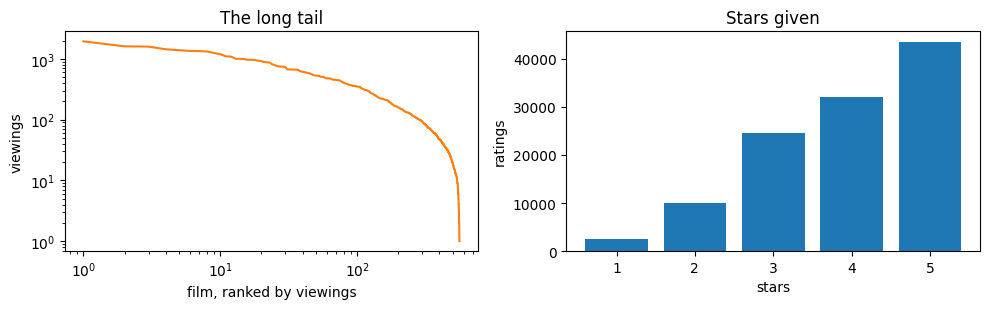

In [3]:
BETA = 0.7                                             # how strongly taste steers the choice
n_per_user = np.clip(rng.lognormal(3.6, 0.5, N_USERS), 12, 150).astype(int)
choice_logit = np.log(popularity)[None, :] + BETA * affinity
choice_p = np.exp(choice_logit - choice_logit.max(axis=1, keepdims=True))
choice_p /= choice_p.sum(axis=1, keepdims=True)

all_u, all_i = [], []
for user in range(N_USERS):                            # each row order is the order in time
    films = rng.permutation(rng.choice(N_ITEMS, n_per_user[user], replace=False, p=choice_p[user]))
    all_u.append(np.full(len(films), user)); all_i.append(films)
all_u, all_i = np.concatenate(all_u), np.concatenate(all_i)

is_new = all_i >= N_OLD                                # viewings of the 40 new releases: kept for Step 17
launch_u, launch_i = all_u[is_new], all_i[is_new]
u, i = all_u[~is_new].astype("int32"), all_i[~is_new].astype("int32")      # the catalogue's history
N = len(u)

device = rng.integers(0, DEVICES, N)                   # 0 = phone
minute = rng.integers(0, 60, N).astype("float32")      # minute of the hour: means nothing
queue = rng.exponential(1.0, N).astype("float32")      # films waiting in the user's list: means nothing
clean = (3.0 + generous[u] + quality[i] + 0.6 * affinity[u, i]
         - 0.6 * ((length[i] > 130) & (age[u] < 30)) - 0.3 * (device == 0))
stars = np.clip(np.round(clean + rng.normal(0, 0.6, N)), 1, 5).astype("float32")

count_all = np.bincount(i, minlength=N_OLD)
print(f"catalogue viewings: {N:,} | viewings of new releases (set aside): {len(launch_u):,}")
print(f"user x film cells: {N_USERS * N_OLD:,} | filled: {100 * N / (N_USERS * N_OLD):.1f}%")
print(f"top 10% of films collect {100 * np.sort(count_all)[::-1][:N_OLD // 10].sum() / N:.1f}% of viewings;"
      f" most watched {count_all.max():,}, median {int(np.median(count_all))}, least {count_all.min()}")
print("share of 1 to 5 stars:", np.round(np.bincount(stars.astype(int), minlength=6)[1:] / N, 3), "| mean", round(float(stars.mean()), 2))
every_pair = (3.0 + generous[:, None] + quality[None, :N_OLD] + 0.6 * affinity[:, :N_OLD]
              - 0.6 * ((length[None, :N_OLD] > 130) & (age[:, None] < 30)) - 0.3 / DEVICES)
print(f"mean stars if every user had rated every film (the formula, no noise): {np.clip(every_pair, 1, 5).mean():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].loglog(np.arange(1, N_OLD + 1), np.sort(count_all)[::-1], color="tab:orange")
ax[0].set(title="The long tail", xlabel="film, ranked by viewings", ylabel="viewings")
ax[1].bar(range(1, 6), np.bincount(stars.astype(int), minlength=6)[1:], color="tab:blue")
ax[1].set(title="Stars given", xlabel="stars", ylabel="ratings")
plt.tight_layout(); plt.show()

### Why we see this

The average given rating is far above what the formula gives for an average user and film (the last print),
because people rate what they chose, and they chose what suited them. A missing rating is therefore **not a
zero and not an average rating**: the empty cells are mostly films the user would have liked less. The top tenth of the catalogue collects about two fifths of all viewings. That skew makes
"recommend the most popular" a serious opponent in Step 11.

About 7% of the user × film cells are filled. That is far denser than real life: at 1 million users,
100,000 items and 50 interactions each, 99.95% of the cells are empty.

---
## Step 4 - Split by time, and prove that nothing leaks

The model will be used on what a user does **next**, so the test set is each user's **last three** viewings.
The three before those are the validation set, for choosing settings. Everything earlier is training data.

> **Predict:** a user never watches a film twice here. So can a (user, film) pair in the test set also
> appear in the training set? What would it mean for the score if it could?

In [4]:
n_old_per_user = np.bincount(u, minlength=N_USERS)
first_row = np.cumsum(n_old_per_user) - n_old_per_user
from_end = n_old_per_user[u] - 1 - (np.arange(N) - first_row[u])     # 0 = the user's latest viewing

test = from_end < 3
val = (from_end >= 3) & (from_end < 6)
train = from_end >= 6
print(f"train {train.sum():,} | validation {val.sum():,} | test {test.sum():,}")
print("fewest training viewings for one user:", np.bincount(u[train], minlength=N_USERS).min())

pair = u.astype(np.int64) * N_OLD + i
assert len(np.unique(pair)) == N                                      # no pair occurs twice anywhere
assert len(np.intersect1d(pair[train], pair[test])) == 0
print("pairs shared by train and test:", len(np.intersect1d(pair[train], pair[test])))

rmse = lambda y, p: float(np.sqrt(np.mean((y - p) ** 2)))
y_train, y_val, y_test = stars[train], stars[val], stars[test]
scores = {}                                                           # the scoreboard of part one

train 94,511 | validation 9,000 | test 9,000
fewest training viewings for one user: 3
pairs shared by train and test: 0


### Why we see this

Every user appears in all three sets, but with different films, and the test films come later in time. A
random split of the rows would have looked similar here, because this little world does not drift. In a real
log it would not: tastes move, films age, and a random split lets the model study the future.

---
# Part one: a table

## Step 5 - Look at the table

One row per viewing. Six numeric columns, four categorical columns with a handful of values each, and two
id columns with thousands and hundreds of values. The target is `stars`.

> **Predict:** which two columns were described above as meaning nothing? A model has no way to know that.
> Which kind of model do you expect to be hurt more by useless columns?

In [5]:
num_names = ["age", "year", "budget", "length", "minute", "queue"]
cat_names = ["region", "plan", "genre", "device"]
CARD = [REGIONS, PLANS, len(GENRES), DEVICES]
X_num = np.stack([age[u], year[i], budget[i], length[i], minute, queue], axis=1).astype("float32")
X_cat = np.stack([region[u], plan[u], genre[i], device], axis=1).astype("int32")

print("  ".join(f"{n:>9}" for n in ["user", "film"] + num_names + cat_names + ["stars"]))
for r in range(5):
    cells = [u[r], i[r]] + [f"{v:.0f}" if k != 5 else f"{v:.2f}" for k, v in enumerate(X_num[r])] + list(X_cat[r]) + [int(stars[r])]
    print("  ".join(f"{str(c):>9}" for c in cells))
print("\nnumeric columns:", X_num.shape, "| categorical columns:", X_cat.shape, "| values per categorical:", CARD)

     user       film        age       year     budget     length     minute      queue     region       plan      genre     device      stars
        0        103         53       2003   16836940        121         38       0.58          3          1          7          1          5
        0        507         53       2015  482965664         99         33       0.05          3          1          3          0          5
        0        434         53       2001   62198180        140         42       0.32          3          1          7          2          4
        0        528         53       2025   38099088        103         20       0.90          3          1          5          0          4
        0        223         53       2013     968604        129          4       1.47          3          1          7          3          4

numeric columns: (112511, 6) | categorical columns: (112511, 4) | values per categorical: [10, 3, 8, 4]


### Why we see this

Nothing in this table has a neighbour. Swap the `age` and `length` columns and the table says exactly the
same thing, so there is nothing for a convolution or an attention layer to exploit. Each column is its own
kind of thing, on its own scale.

---
## Step 6 - The baselines, and the floor

Before any model, three guesses that need no learning beyond averages:

1. the **global mean** of the training ratings, for everyone;
2. the **film's mean** rating (pulled towards the global mean when the film has few ratings);
3. the film's mean **plus the user's mean** leftover (is this user an easy or a hard marker?).

And one number no model can beat: the **floor**. The notebook knows the formula behind every rating, so it
can predict with the formula itself. What remains is the noise and the rounding.

> **Predict:** the ratings have a standard deviation of about 1.07 stars. How much of that do you expect
> the two means to remove? Where do you expect the floor: 0.2, 0.55 or 0.9?

In [6]:
g_mean = float(y_train.mean())

def shrunk_mean(keys, values, n, shrink=5.0):
    """Mean of `values` per key, pulled towards 0 for keys with few rows."""
    return np.bincount(keys, weights=values, minlength=n) / (np.bincount(keys, minlength=n) + shrink)

film_mean = shrunk_mean(i[train], y_train - g_mean, N_OLD)
user_mean = shrunk_mean(u[train], y_train - g_mean - film_mean[i[train]], N_USERS)
clip = lambda p: np.clip(p, 1, 5)

scores["global mean"] = rmse(y_test, g_mean)
scores["film mean"] = rmse(y_test, clip(g_mean + film_mean[i[test]]))
scores["film mean + user mean"] = rmse(y_test, clip(g_mean + film_mean[i[test]] + user_mean[u[test]]))
floor = rmse(y_test, clip(clean[test]))
for name, s in scores.items():
    print(f"{name:26s} test RMSE {s:.3f}")
print(f"{'floor (the true formula)':26s} test RMSE {floor:.3f}")

global mean                test RMSE 1.072
film mean                  test RMSE 0.970
film mean + user mean      test RMSE 0.874
floor (the true formula)   test RMSE 0.555


### Why we see this

Two tables of averages take the error from 1.07 to 0.87 stars. They are the first rows of every rating
scoreboard, and published comparisons have more than once found newer models failing to beat well-tuned
versions of them. The floor is about 0.56: with 0.6 stars of noise and rounding to whole stars, nobody gets
below it. So the whole contest takes place between 0.87 and 0.56.

---
## Step 7 - The feature table: a linear model and gradient-boosted trees

Now use the ten ordinary columns (not the ids yet).

* A **linear model** (ridge regression, written in four lines of NumPy): numeric columns standardised,
  categorical columns one-hot.
* **Gradient-boosted trees** (`HistGradientBoostingRegressor` from scikit-learn, if installed): raw columns,
  no scaling at all, the four categorical columns marked as categorical.

> **Predict:** the formula contains "under 30 **and** longer than 130 minutes", and "region × genre" hides
> inside the affinity. Which of the two models can express an "and" between two columns?

In [7]:
def standardise(X):
    mu, sd = X[train].mean(axis=0), X[train].std(axis=0)             # statistics from the training rows only
    return ((X - mu) / sd).astype("float32")

def one_hot(X, cards):
    return np.concatenate([np.eye(c, dtype="float32")[X[:, k]] for k, c in enumerate(cards)], axis=1)

X_lin = np.concatenate([standardise(X_num), one_hot(X_cat, CARD), np.ones((N, 1), "float32")], axis=1)
A = X_lin[train]
w_ridge = np.linalg.solve(A.T @ A + 1.0 * np.eye(A.shape[1]), A.T @ (y_train - g_mean))
scores["linear, features"] = rmse(y_test, clip(g_mean + X_lin[test] @ w_ridge))
print(f"linear model on {X_lin.shape[1]} columns      test RMSE {scores['linear, features']:.3f}")

X_tree = np.concatenate([X_num, X_cat], axis=1)                       # raw numbers: no scaling, no one-hot
CAT_COLS = [6, 7, 8, 9]

def fit_tree(X, name):
    if not HAVE_SKLEARN:
        print(f"{name:34s} skipped: scikit-learn is not installed")
        return None
    t0 = time.time()
    model = HistGradientBoostingRegressor(max_iter=1000, learning_rate=0.08, categorical_features=CAT_COLS,
                                          early_stopping=True, random_state=SEED)
    model.fit(X[train], y_train)
    scores[name] = rmse(y_test, clip(model.predict(X[test])))
    print(f"{name:34s} test RMSE {scores[name]:.3f}   ({model.n_iter_} trees, {time.time() - t0:.1f} s)")
    return model

tree_features = fit_tree(X_tree, "trees, features")

linear model on 32 columns      test RMSE 1.030


trees, features                    test RMSE 0.895   (313 trees, 3.0 s)


### Why we see this

The linear model adds up one effect per column. It cannot say "long **and** young", and it cannot say "this
region likes this genre". The trees can: a split on `length` followed by a split on `age` is exactly an
"and". They took the raw dollars of `budget` without complaint, ignored `minute` and `queue`, and finished
in a few seconds with settings nobody tuned.

---
## Step 8 - A network on the same columns: raw, then done properly

The network is a small MLP (Chapter 4). Each categorical column goes through its own small **embedding**
(Chapter 18), the numeric columns go in as they are, everything is concatenated, and two Dense layers follow.

Run it twice: once on the **raw** numeric columns, once with them **prepared** (log of `budget`, then every
numeric column standardised with the training rows' mean and spread).

> **Predict the parameter count.** Embeddings: region 10 × 4, plan 3 × 2, genre 8 × 4, device 4 × 2. The
> concatenated width is 6 + 4 + 2 + 4 + 2 = 18. Then Dense(64), Dense(32), Dense(1).
>
> **Predict:** on the same ten columns, will the prepared network beat the trees?

In [8]:
EMB = [4, 2, 4, 2]                                                    # embedding width for each categorical

def build_mlp(with_ids=False, d_id=16):
    num_in = layers.Input(shape=(6,), name="numeric")
    cat_in = layers.Input(shape=(4,), dtype="int32", name="categorical")
    parts = [num_in] + [layers.Embedding(CARD[k], EMB[k])(cat_in[:, k]) for k in range(4)]
    inputs = [num_in, cat_in]
    if with_ids:
        user_in = layers.Input(shape=(), dtype="int32", name="user")
        film_in = layers.Input(shape=(), dtype="int32", name="film")
        reg = keras.regularizers.l2(5e-5)                            # ids memorise easily: hold them back
        parts += [layers.Embedding(N_USERS, d_id, embeddings_regularizer=reg)(user_in),
                  layers.Embedding(N_OLD, d_id, embeddings_regularizer=reg)(film_in)]
        inputs += [user_in, film_in]
    h = layers.Concatenate()(parts)
    h = layers.Dense(64, activation="relu")(h)
    h = layers.Dropout(0.1)(h)
    h = layers.Dense(32, activation="relu")(h)
    return keras.Model(inputs, layers.Dense(1)(h))

def train_mlp(name, numeric, with_ids=False, max_epochs=60):
    keras.utils.set_random_seed(SEED)
    model = build_mlp(with_ids)
    model.compile(keras.optimizers.Adam(2e-3), loss="mse", metrics=[keras.metrics.RootMeanSquaredError(name="rmse")])
    feed = lambda rows: [numeric[rows], X_cat[rows]] + ([u[rows], i[rows]] if with_ids else [])
    stop = keras.callbacks.EarlyStopping(monitor="val_rmse", patience=3, restore_best_weights=True)
    t0 = time.time()
    hist = model.fit(feed(train), y_train - g_mean, validation_data=(feed(val), y_val - g_mean),
                     epochs=max_epochs, batch_size=256, verbose=0, callbacks=[stop])
    pred = clip(g_mean + model.predict(feed(test), batch_size=4096, verbose=0)[:, 0])
    scores[name] = rmse(y_test, pred)
    print(f"{name:34s} test RMSE {scores[name]:.3f}   ({model.count_params():,} parameters,"
          f" {len(hist.history['loss'])} epochs, {time.time() - t0:.0f} s)")
    return model

emb_params = sum(c * e for c, e in zip(CARD, EMB))
width = 6 + sum(EMB)
mlp_params = emb_params + (width * 64 + 64) + (64 * 32 + 32) + (32 + 1)
print(f"by hand: embeddings {emb_params} + Dense {width * 64 + 64} + {64 * 32 + 32} + {32 + 1} = {mlp_params:,}")
assert build_mlp().count_params() == mlp_params == 3415

X_prepared = X_num.copy()
X_prepared[:, 2] = np.log(X_prepared[:, 2])                           # dollars -> log dollars
X_prepared = standardise(X_prepared)
mlp_raw = train_mlp("MLP, raw columns", X_num)
mlp_feat = train_mlp("MLP, prepared columns", X_prepared)

by hand: embeddings 86 + Dense 1216 + 2080 + 33 = 3,415


MLP, raw columns                   test RMSE 3.145   (3,415 parameters, 11 epochs, 8 s)


MLP, prepared columns              test RMSE 0.934   (3,415 parameters, 21 epochs, 13 s)


### Why we see this

Fed raw dollars, the network is far worse than guessing the global mean. One input in the tens of millions
swamps every other column: the first Dense layer's sums are dominated by `budget`, and the gradient steps
that suit it are wrong for everything else (Chapter 2 gave the rule, Chapter 8 the reason).

Prepared properly, the same 3,415 parameters do far better, but on these ten columns they do **not** catch
the trees. Look at your own run for the exact gap. This is the usual result on a table of ordinary columns,
and it is why Chapter 31 said "trees first". The network needed scaling, a log, embeddings, dropout, early
stopping and many epochs to get this close. The trees needed none of it.

---
## Step 9 - Give both models the ids

Two columns have been held back: `user` (3,000 values) and `film` (560 values). They are the interesting
ones. The visible columns explain only part of a user's taste. The rest is personal, and the only handle on
it is the id.

* The **network** gets two more embedding columns, 16 numbers per user and 16 per film.
* The **trees** get the ids in the two ways a tree can take them: as **raw integers** (user 1,207 is "more"
  than user 1,206, which means nothing), and as **target means** (each id replaced by its average leftover
  rating: the two baselines of Step 6 as columns). The target means are computed **out of fold**, so that no
  training row sees an average that includes its own rating.

> **Predict the parameter count** of the network with id columns: user table 3,000 × 16, film table
> 560 × 16, concatenated width 18 + 32 = 50. What share of all parameters sits in the two id tables?
>
> **Predict:** who wins now, and by more or less than in Step 8?

In [9]:
id_params = N_USERS * 16 + N_OLD * 16
mlp_id_params = emb_params + id_params + ((width + 32) * 64 + 64) + (64 * 32 + 32) + (32 + 1)
print(f"by hand: id tables {id_params:,} + the rest {mlp_id_params - id_params:,} = {mlp_id_params:,}"
      f"  ({100 * id_params / mlp_id_params:.0f}% in the id tables)")
assert build_mlp(with_ids=True).count_params() == mlp_id_params == 62423
mlp_ids = train_mlp("MLP + id embeddings", X_prepared, with_ids=True)

# trees with the ids as raw integers
tree_raw_ids = fit_tree(np.concatenate([X_tree, u[:, None], i[:, None]], axis=1), "trees + raw ids")

# trees with the ids as out-of-fold target means
fold = rng.integers(0, 5, N)
te_film, te_user = film_mean[i].copy(), user_mean[u].copy()          # validation and test rows: training means
for f in range(5):
    fit, hold = train & (fold != f), train & (fold == f)
    fm = shrunk_mean(i[fit], stars[fit] - g_mean, N_OLD)
    um = shrunk_mean(u[fit], stars[fit] - g_mean - fm[i[fit]], N_USERS)
    te_film[hold], te_user[hold] = fm[i[hold]], um[u[hold]]
tree_means = fit_tree(np.concatenate([X_tree, te_film[:, None], te_user[:, None]], axis=1), "trees + id target means")

by hand: id tables 56,960 + the rest 5,463 = 62,423  (91% in the id tables)


MLP + id embeddings                test RMSE 0.690   (62,423 parameters, 15 epochs, 12 s)


trees + raw ids                    test RMSE 0.861   (629 trees, 2.6 s)


trees + id target means            test RMSE 0.823   (269 trees, 1.2 s)


### Why we see this

The id tables hold nine tenths of the network's parameters, and they are what turns the result round.

As raw integers the ids give the trees little: the numbering is an accident, and a split such as
"user id below 1,500" separates nothing real. As target means they help more, because a mean captures
whether a user is generous and whether a film is good: one number per id.

The embedding gives each id **sixteen** numbers and lets the network learn what they should mean. That is
enough to hold a personal taste: not "this user rates high" but "this user rates *this kind of film* high".
One number per id cannot say that, and neither can any visible column. It is the 0.6 × affinity term of the
formula, and only the model with embeddings gets at its personal part.

---
## Step 10 - The scoreboard of part one

model                        test RMSE   share of the possible gain
MLP, raw columns              3.145     -400.7%
global mean                   1.072       0.0%
linear, features              1.030       8.2%
film mean                     0.970      19.7%
MLP, prepared columns         0.934      26.7%
trees, features               0.895      34.2%
film mean + user mean         0.874      38.3%
trees + raw ids               0.861      40.7%
trees + id target means       0.823      48.2%
MLP + id embeddings           0.690      73.9%
floor (the true formula)      0.555     100.0%


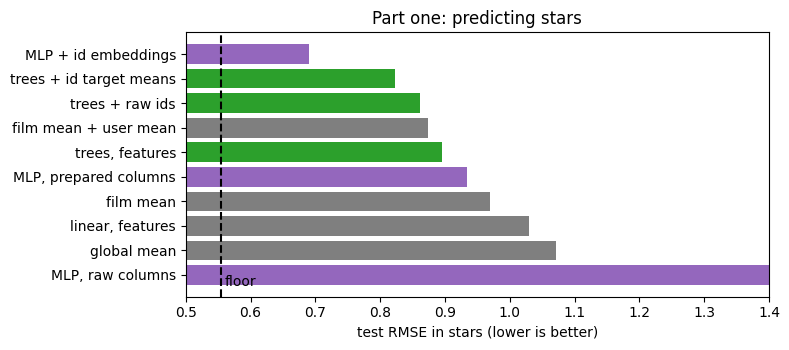

In [10]:
order = sorted(scores, key=scores.get, reverse=True)
print(f"{'model':28s} test RMSE   share of the possible gain")
top = scores["global mean"]
for name in order:
    print(f"{name:28s}  {scores[name]:.3f}     {100 * (top - scores[name]) / (top - floor):5.1f}%")
print(f"{'floor (the true formula)':28s}  {floor:.3f}     100.0%")

colour = lambda n: "tab:green" if n.startswith("trees") else "tab:purple" if n.startswith("MLP") else "tab:gray"
plt.figure(figsize=(8, 3.6))
plt.barh(order, [scores[n] for n in order], color=[colour(n) for n in order])
plt.axvline(floor, color="black", linestyle="--"); plt.text(floor + 0.005, -0.3, "floor", va="center")
plt.xlim(0.5, max(1.15, min(scores["MLP, raw columns"] + 0.02, 1.4))); plt.xlabel("test RMSE in stars (lower is better)")
plt.title("Part one: predicting stars"); plt.tight_layout(); plt.show()

### Why we see this

Read the board in three bands.

* **Ordinary columns only:** trees ahead of the prepared network, both ahead of the linear model. The film
  and user means alone beat all three, which tells you where the information is: in the ids.
* **Ids as one number each:** trees with target means. A strong, cheap model, and the one to beat.
* **Ids as learnt vectors:** the network with embeddings, alone in the last band.

"The share of the possible gain" measures each model between the global mean (0%) and the floor (100%).

This is a designed world: the affinity term was made large enough for the lesson to show. The pattern is the
honest part. A network earns its place on a table when a column has so many values that the useful thing to
learn about each value is a **vector**.

---
# Part two: retrieval

## Step 11 - From stars to choices, and the baseline to beat

A service rarely asks "how many stars?". It asks "which ten films do I show?". And most users never rate
anything: what the service has is **implicit feedback**, the plain fact that a user chose a film. So forget
the stars. Every training viewing is now one positive example, and there are no negative examples at all.

The score is **recall@10**: recommend 10 films to each user, and count what fraction of the user's held-out
films are among them. Films the user has already watched are never recommended (they are **masked**),
because recommending them is useless and, with repeats impossible here, always wrong.

Three references before any model: ten **random** films, the ten **most popular** films, and the **hidden
truth**: ranking by the very formula that generated the choices.

> **Predict:** random scores 10 in 560 at best. Where will "most popular" land: 3%, 10% or 20%? And the
> hidden truth: can even it reach 100%?

In [11]:
seen_train = np.zeros((N_USERS, N_OLD), dtype=bool); seen_train[u[train], i[train]] = True
seen_before_test = seen_train.copy(); seen_before_test[u[val], i[val]] = True
assert not seen_before_test[u[test], i[test]].any()                   # no test film was seen before

def recall_at_k(score, rows=test, seen=seen_before_test, k=10):
    """score: (users, films). Fraction of held-out viewings found in the user's top k unseen films."""
    s = np.where(seen, -np.inf, score) if seen is not None else score
    top = np.argpartition(-s, k, axis=1)[:, :k]
    return float((top[u[rows]] == i[rows][:, None]).any(axis=1).mean())

u_tr, i_tr = u[train], i[train]
count_train = np.bincount(i_tr, minlength=N_OLD).astype("float64")
recall = {}
recall["random"] = recall_at_k(rng.random((N_USERS, N_OLD)))
recall["most popular"] = recall_at_k(np.tile(count_train, (N_USERS, 1)))
truth_score = np.log(popularity[:N_OLD])[None, :] + BETA * affinity[:, :N_OLD]
recall["hidden truth"] = recall_at_k(truth_score)
recall["taste alone (truth, no popularity)"] = recall_at_k(affinity[:, :N_OLD])
for name, r in recall.items():
    print(f"{name:36s} recall@10 {100 * r:5.1f}%")
print(f"\nheld-out viewings scored: {test.sum():,} (3 per user) | candidates per user: up to {N_OLD}")

random                               recall@10   1.9%
most popular                         recall@10  20.8%
hidden truth                         recall@10  38.5%
taste alone (truth, no popularity)   recall@10  15.0%

held-out viewings scored: 9,000 (3 per user) | candidates per user: up to 560


### Why we see this

One list for everybody, with no model and no personalisation, finds more than a fifth of what users watch
next. That is eleven times the random baseline, and it is the number a recommender has to beat. Any report
that compares only with random is hiding this row.

Even the hidden truth is far from 100%. Choice is a lottery weighted by popularity and taste, and ten
guesses cannot cover it. Notice also that perfect knowledge of every user's taste, **without** popularity,
scores below the popular list. Popularity is not a bias to be removed from the answer. It is half the answer.

---
## Step 12 - In-batch negatives, by hand

The model will give every user a vector and every film a vector, and score a pair by their dot product.
Training needs wrong answers as well as right ones, and nobody recorded "films this user refused". The
trick is the contrastive one of Chapters 48 and 49: take a batch of B (user, film) pairs. For user k, film k
is the right answer and **the other B − 1 films in the batch are treated as wrong answers**. The loss is
cross-entropy on each row of the B × B table of dot products, the same shape as `info_nce` in the Chapter 48
lab (which also normalised the vectors and divided by a temperature; here the plain dot product is kept).

> **Predict:** four pairs, with the vectors below. User 0's own film scores 2.0 against it, and the other
> three films −1.0, −1.0 and 1.0. Which user's row will have the highest loss? And what is the loss of a model that knows
> nothing, for B = 4 and for B = 512?

In [12]:
def in_batch_loss(user_vecs, item_vecs, log_q=None, item_ids=None):
    """Row k: user k's dot product with every film in the batch. Film k is right, the rest are negatives.
    log_q: log of each batch film's share of the training viewings, subtracted to undo the popularity bias.
    item_ids: if given, a film that occurs twice in the batch is not used as a negative for itself."""
    logits = tf.matmul(user_vecs, item_vecs, transpose_b=True)        # (B, B)
    if log_q is not None:
        logits = logits - log_q[None, :]
    if item_ids is not None:
        twin = tf.equal(item_ids[:, None], item_ids[None, :]) & ~tf.eye(tf.shape(item_ids)[0], dtype=tf.bool)
        logits = tf.where(twin, -1e9, logits)
    labels = tf.range(tf.shape(logits)[0])                            # the partner of row k is column k
    rows = keras.losses.sparse_categorical_crossentropy(labels, logits, from_logits=True)
    return tf.reduce_mean(rows), logits

toy_users = np.array([[1.0, 1.0], [1.0, -1.0], [-1.0, 0.5], [0.5, 0.5]], dtype="float32")
toy_films = np.array([[1.0, 1.0], [0.5, -1.5], [-2.0, 1.0], [1.5, -0.5]], dtype="float32")
toy_logits = toy_users @ toy_films.T
print("table of dot products (rows: users, columns: films)\n", toy_logits)
toy_rows = np.array([-np.log(np.exp(r[k]) / np.exp(r).sum()) for k, r in enumerate(toy_logits)])
print("loss of each row by hand:", toy_rows.round(3), "| mean", toy_rows.mean().round(4))
toy_loss, _ = in_batch_loss(tf.constant(toy_users), tf.constant(toy_films))
assert abs(float(toy_loss) - toy_rows.mean()) < 1e-5
print("in_batch_loss:", round(float(toy_loss), 4), "| knows nothing: ln 4 =", round(float(np.log(4)), 3), "| ln 512 =", round(float(np.log(512)), 3))

# who are the negatives? look at one real batch of 512 training viewings
batch = rng.choice(len(u_tr), 512, replace=False)
top_tenth = np.argsort(-count_train)[:N_OLD // 10]
print(f"\nin a batch of 512: {100 * np.isin(i_tr[batch], top_tenth).mean():.0f}% of the films come from the top 10% of the"
      f" catalogue (uniform negatives would give 10%); {512 - len(np.unique(i_tr[batch]))} films are repeats")

table of dot products (rows: users, columns: films)
 [[ 2.   -1.   -1.    1.  ]
 [ 0.    2.   -3.    2.  ]
 [-0.5  -1.25  2.5  -1.75]
 [ 1.   -0.5  -0.5   0.5 ]]
loss of each row by hand: [0.384 0.762 0.084 1.219] | mean 0.6121
in_batch_loss: 0.6121 | knows nothing: ln 4 = 1.386 | ln 512 = 6.238

in a batch of 512: 45% of the films come from the top 10% of the catalogue (uniform negatives would give 10%); 271 films are repeats


### Why we see this

The last user has the highest loss: its dot product with its own film (0.5) is smaller than with film 0
(1.0), so the row points at the wrong column.

The second print is the important one. In-batch negatives are free, but they are **not a fair sample of the
catalogue**. A film appears in a batch as often as it is watched, so popular films turn up as "wrong
answers" again and again, and obscure films almost never do. A model trained on this learns to mark popular
films down. Step 13 measures the damage and Step 14 repairs it. The repeats matter too: a film that occurs
twice in a batch would be its own negative, which is why the loss can mask them.

---
## Step 13 - Two towers, the simplest way: two lookup tables

A **two-tower model** has a user tower that turns a user into a vector and an item tower that turns a film
into a vector of the same width. The score is their dot product. Start with the simplest possible towers:
each is one embedding table and nothing else. Trained on ratings with squared error, this is called
**matrix factorisation**. Trained on choices with in-batch negatives, it is the two-tower model at its
smallest.

> **Predict the parameter count:** 3,000 users and 560 films, 16 numbers each.
>
> **Predict:** this first run uses the loss with no popularity correction. Will it beat "most popular"?

In [13]:
D = 16
log_q = np.log((count_train + 1) / (count_train + 1).sum()).astype("float32")   # log share of the training viewings
                                                                      # (+1: a film nobody watched yet has no log)

def make_towers(item_features=False):
    """Returns (user_tower, item_tower). Both end in a vector of width D."""
    user_tower = keras.Sequential([layers.Input(shape=(), dtype="int32"), layers.Embedding(N_USERS, D)])
    if not item_features:
        item_tower = keras.Sequential([layers.Input(shape=(), dtype="int32"), layers.Embedding(N_OLD, D)])
    else:                                                             # used in Step 18
        id_in = layers.Input(shape=(), dtype="int32"); genre_in = layers.Input(shape=(), dtype="int32")
        num_in = layers.Input(shape=(3,))
        h = layers.Concatenate()([layers.Embedding(len(GENRES), 4)(genre_in), num_in])
        h = layers.Dense(D)(layers.Dense(32, activation="relu")(h))
        vec = layers.Embedding(N_OLD + 1, D)(id_in) + h                # row N_OLD of the table = "unknown film"
        item_tower = keras.Model([id_in, genre_in, num_in], vec)
    return user_tower, item_tower

def train_two_tower(user_tower, item_tower, item_input, correct, steps=3000, batch_size=512, seed=SEED):
    """item_input(ids, training) -> what the item tower is fed. Returns the list of losses."""
    opt = keras.optimizers.Adam(keras.optimizers.schedules.CosineDecay(5e-3, steps))
    weights = user_tower.trainable_variables + item_tower.trainable_variables
    LOG_Q = tf.constant(log_q)

    @tf.function(autograph=False)
    def step(users, films):
        with tf.GradientTape() as tape:
            loss, _ = in_batch_loss(user_tower(users), item_tower(item_input(films, True)),
                                    log_q=tf.gather(LOG_Q, films) if correct else None, item_ids=films)
        opt.apply_gradients(zip(tape.gradient(loss, weights), weights))
        return loss

    pick, losses = np.random.default_rng(seed), []
    for _ in range(steps):
        rows = pick.choice(len(u_tr), batch_size, replace=False)
        losses.append(float(step(tf.constant(u_tr[rows]), tf.constant(i_tr[rows]))))
    return losses

ids_only = lambda films, training: films
all_users, all_films = tf.range(N_USERS), tf.range(N_OLD)

keras.utils.set_random_seed(SEED)
user_plain, item_plain = make_towers()
assert user_plain.count_params() + item_plain.count_params() == (N_USERS + N_OLD) * D == 56960
print(f"parameters: ({N_USERS:,} + {N_OLD}) x {D} = {(N_USERS + N_OLD) * D:,}")
t0 = time.time()
loss_plain = train_two_tower(user_plain, item_plain, ids_only, correct=False)
U_plain, V_plain = user_plain(all_users).numpy(), item_plain(all_films).numpy()
recall["two towers, plain in-batch loss"] = recall_at_k(U_plain @ V_plain.T)
print(f"loss: start {np.mean(loss_plain[:20]):.2f} (ln 512 = {np.log(512):.2f}), end {np.mean(loss_plain[-100:]):.2f}   ({time.time() - t0:.0f} s)")
print(f"recall@10: two towers, plain loss {100 * recall['two towers, plain in-batch loss']:.1f}%"
      f"  |  most popular {100 * recall['most popular']:.1f}%")
rank_of_popular = np.argsort(np.argsort(-(U_plain @ V_plain.T), axis=1), axis=1)[:, top_tenth].mean()
print(f"average rank given to a top-10% film: {rank_of_popular:.0f} of {N_OLD} (a model blind to popularity would give about {N_OLD // 2})")

parameters: (3,000 + 560) x 16 = 56,960


loss: start 6.23 (ln 512 = 6.24), end 5.58   (6 s)
recall@10: two towers, plain loss 5.6%  |  most popular 20.8%
average rank given to a top-10% film: 269 of 560 (a model blind to popularity would give about 280)


### Why we see this

The loss went down and the model lost to a list that needs no model. This is the trap of Step 12 in action.
The plain in-batch loss asks "which film in this batch did this user pick?", and the batch is full of
popular films that somebody else picked. To answer well, the model learns how much more a user likes a film
**than its popularity alone would predict**. Ranked by that score, the films everyone watches get no head
start: the last print shows them in the middle of the list.

That score is useful (it is the "taste alone" of Step 11, and it is what makes two films similar), but it
is not the probability that the user will watch the film next. A falling loss told us nothing about that.

---
## Step 14 - Correct the popularity bias

The repair is one line, known as the **logQ correction** (used in a 2019 YouTube two-tower system): during
training, subtract from each film's column the log of that film's share of the training viewings. A popular
film that appears as a negative simply because it is everywhere is excused for it. At serving time nothing
is subtracted, so the plain dot product now carries popularity **and** taste.

> **Predict:** same tables, same 56,960 parameters, same data, one line changed. Where does recall@10 land:
> below most-popular, level with it, or above?

trained in 6 s
random                             recall@10   1.9%
two towers, plain in-batch loss    recall@10   5.6%
most popular                       recall@10  20.8%
two towers, logQ-corrected         recall@10  30.2%
hidden truth                       recall@10  38.5%
validation recall@10 (for tuning): 28.8%
correlation of a film vector's length with log popularity: plain +0.31, corrected +0.74


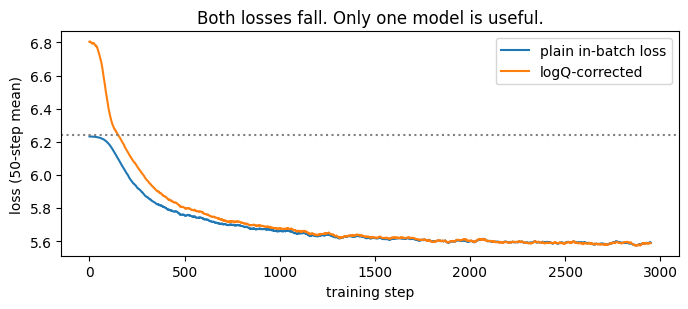

In [14]:
keras.utils.set_random_seed(SEED)
user_tower, item_tower = make_towers()
t0 = time.time()
loss_corr = train_two_tower(user_tower, item_tower, ids_only, correct=True)
U_vec, V_vec = user_tower(all_users).numpy(), item_tower(all_films).numpy()
score_tt = U_vec @ V_vec.T
recall["two towers, logQ-corrected"] = recall_at_k(score_tt)
print(f"trained in {time.time() - t0:.0f} s")
for name in ["random", "two towers, plain in-batch loss", "most popular", "two towers, logQ-corrected", "hidden truth"]:
    print(f"{name:34s} recall@10 {100 * recall[name]:5.1f}%")
print(f"validation recall@10 (for tuning): {100 * recall_at_k(score_tt, rows=val, seen=seen_train):.1f}%")
norm = np.linalg.norm(V_vec, axis=1)
print(f"correlation of a film vector's length with log popularity: plain {np.corrcoef(np.linalg.norm(V_plain, axis=1), np.log(count_train + 1))[0, 1]:+.2f},"
      f" corrected {np.corrcoef(norm, np.log(count_train + 1))[0, 1]:+.2f}")

plt.figure(figsize=(7, 3.2))
smooth = lambda x: np.convolve(x, np.ones(50) / 50, mode="valid")
plt.plot(smooth(loss_plain), label="plain in-batch loss"); plt.plot(smooth(loss_corr), label="logQ-corrected")
plt.axhline(np.log(512), color="gray", linestyle=":"); plt.xlabel("training step"); plt.ylabel("loss (50-step mean)")
plt.title("Both losses fall. Only one model is useful."); plt.legend(); plt.tight_layout(); plt.show()

### Why we see this

One line took the same model from far below the popular list to well above it, and about half of the way
from the popular list to the hidden truth. The personalisation was there in the first model too. It was pointed at the wrong question.

The two loss curves are not comparable with each other (the correction changes what is being asked), and
neither told you which model recommends better. **Only the retrieval metric on held-out viewings did.**

These are small-model numbers on 560 films. A real catalogue has millions of items, recall@10 is far lower,
and retrieval hands hundreds of candidates to a second, heavier ranking model.

---
## Step 15 - Three ways to fool yourself with this metric

The model is fixed. Only the evaluation changes.

1. **Forget the mask:** let the model recommend films the user has already watched.
2. **Rank against a sample:** a common shortcut ranks each held-out film against only 99 randomly drawn
   films, not the whole catalogue, and reports "recall@10" on that.
3. **Compare with random only:** leave "most popular" out of the report.

> **Predict:** which of the first two makes the model look worse than it is, and which makes it look better?
> By how much?

In [15]:
honest = recall["two towers, logQ-corrected"]
no_mask = recall_at_k(score_tt, seen=None)
top10 = np.argsort(-score_tt, axis=1)[:, :10]
already = seen_before_test[np.arange(N_USERS)[:, None], top10].mean()

def sampled_recall(score, n_neg=99, k=10):
    """The held-out film against n_neg random films: a hit if fewer than k of them outscore it."""
    neg = rng.integers(0, N_OLD, (int(test.sum()), n_neg))
    s_pos, s_neg = score[u[test], i[test]], score[u[test][:, None], neg]
    return float(((s_neg > s_pos[:, None]).sum(axis=1) < k).mean())

pop_score = np.tile(count_train, (N_USERS, 1))
print(f"honest: whole catalogue, seen films masked    two towers {100 * honest:5.1f}%   most popular {100 * recall['most popular']:5.1f}%")
print(f"1. no mask                                    two towers {100 * no_mask:5.1f}%   ({100 * already:.0f}% of its recommendations had already been watched)")
print(f"2. ranked against 99 sampled films            two towers {100 * sampled_recall(score_tt):5.1f}%   most popular {100 * sampled_recall(pop_score):5.1f}%")
print(f"3. 'beats random by {honest / recall['random']:.0f} times'                 ... and most popular already beats random by {recall['most popular'] / recall['random']:.0f} times")

honest: whole catalogue, seen films masked    two towers  30.2%   most popular  20.8%
1. no mask                                    two towers  12.5%   (73% of its recommendations had already been watched)
2. ranked against 99 sampled films            two towers  51.7%   most popular  44.1%
3. 'beats random by 16 times'                 ... and most popular already beats random by 11 times


### Why we see this

Without the mask, most of the ten slots are spent on films the user has already watched. The model is doing
what it was trained to do (score watched films high), and the evaluation wastes its list. In a product this
is the "you bought a kettle, here are six kettles" failure.

The sampled shortcut does the opposite: with 99 opponents in place of 559, the same model appears to find
most of what users watch next. The number is not wrong arithmetic, it is a different and much easier exam,
and it can even change which of two models looks better. If a reported recall seems too good, look for the
word "sampled".

---
## Step 16 - Did the film vectors find the hidden traits?

The model was never shown a genre or a trait. It saw only who watched what. Two tests of what the 560 film
vectors learnt:

* **Neighbours:** for each film, find its 5 nearest films by cosine similarity (Chapter 18). How often do
  they share its genre?
* **A linear probe** (Chapter 48): fit a straight-line map from the 16 learnt numbers to the 4 hidden traits
  on 400 films, and test it on the other 160. R² = 1 would mean the traits can be read off perfectly.

> **Predict:** eight genres, so a random neighbour shares the genre about one time in eight. What do you
> expect from the learnt vectors: 15%, 40% or 90%? Remember that genre sets most, but not all, of a trait.

neighbours sharing the film's genre: chance 13% | random vectors 13% | learnt vectors 48% | the hidden traits themselves 59%
linear probe, learnt vectors -> hidden traits: R^2 = 0.90 (random vectors: -0.04)


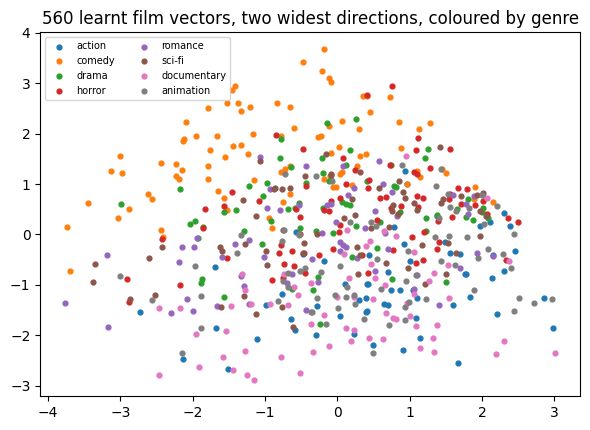

In [16]:
def neighbour_genre_match(V, k=5):
    Vn = V / np.linalg.norm(V, axis=1, keepdims=True)
    sim = Vn @ Vn.T
    np.fill_diagonal(sim, -np.inf)
    near = np.argsort(-sim, axis=1)[:, :k]
    return float((genre[:N_OLD][near] == genre[:N_OLD][:, None]).mean())

def probe_r2(V, target):
    perm = np.random.default_rng(0).permutation(N_OLD)
    fit, hold = perm[:400], perm[400:]
    A = np.concatenate([V, np.ones((N_OLD, 1))], axis=1)
    W = np.linalg.lstsq(A[fit], target[fit], rcond=None)[0]
    resid = ((target[hold] - A[hold] @ W) ** 2).sum()
    return float(1 - resid / ((target[hold] - target[fit].mean(axis=0)) ** 2).sum())

chance = float((np.bincount(genre[:N_OLD]) / N_OLD) @ (np.bincount(genre[:N_OLD]) / N_OLD))
V_random = np.random.default_rng(1).normal(size=(N_OLD, D))
print(f"neighbours sharing the film's genre: chance {100 * chance:.0f}% | random vectors {100 * neighbour_genre_match(V_random):.0f}%"
      f" | learnt vectors {100 * neighbour_genre_match(V_vec):.0f}% | the hidden traits themselves {100 * neighbour_genre_match(trait[:N_OLD]):.0f}%")
print(f"linear probe, learnt vectors -> hidden traits: R^2 = {probe_r2(V_vec, trait[:N_OLD]):.2f}"
      f" (random vectors: {probe_r2(V_random, trait[:N_OLD]):.2f})")

Vc = V_vec - V_vec.mean(axis=0)
xy = Vc @ np.linalg.svd(Vc, full_matrices=False)[2][:2].T             # the two widest directions
plt.figure(figsize=(6, 4.4))
for gi, gname in enumerate(GENRES):
    pts = xy[genre[:N_OLD] == gi]
    plt.scatter(pts[:, 0], pts[:, 1], s=12, label=gname)
plt.legend(fontsize=7, ncol=2); plt.title("560 learnt film vectors, two widest directions, coloured by genre")
plt.tight_layout(); plt.show()

### Why we see this

Nobody told the model about genres, and films of one genre ended up near each other anyway, because the
same users watch them. That is **collaborative filtering**: "people who chose this also chose that" is
enough to recover what the films have in common. The probe says the hidden traits can largely be read off
the learnt vectors with a straight-line map.

The learnt space is not the hidden space itself. It is rotated and stretched, has 16 directions where the
truth has 4, and some of its directions carry popularity. Only its geometry (who is near whom) is meaningful.

---
## Step 17 - Cold start: forty new films

Forty films are released. Nobody has watched them yet, so the training data never mentioned them. Their
rows in a lookup table would be the random numbers they were initialised with.

The test: the "new releases" shelf. For every real viewing of a new film (set aside in Step 3), rank the 40
new films for that user and ask whether the one they chose is in the **top 5**. Chance is 5 in 40.
"Most popular" cannot even play: a new film has no count.

> **Predict:** what will a lookup-table tower score on films it has never seen? And how well does the
> hidden truth do with only 40 candidates, with and without knowing how popular each new film will be?

In [17]:
def shelf_recall(user_vecs, new_vecs, k=5):
    s = user_vecs @ new_vecs.T                                         # (users, 40)
    top = np.argpartition(-s, k, axis=1)[:, :k] + N_OLD
    return float((top[launch_u] == launch_i[:, None]).any(axis=1).mean())

print(f"viewings of new films to score: {len(launch_u):,} | candidates: {N_NEW} | chance: {100 * 5 / N_NEW:.1f}%")
# a new film's row holds what Keras initialised it with: small random numbers. Try 100 such draws.
draws = [shelf_recall(U_vec, np.random.default_rng(k).uniform(-0.05, 0.05, (N_NEW, D))) for k in range(100)]
print(f"lookup table with untrained rows, 100 draws: mean {100 * np.mean(draws):.1f}%, from {100 * np.min(draws):.1f}% to {100 * np.max(draws):.1f}%")
shelf = {}
shelf["lookup table (untrained rows)"] = float(np.mean(draws))
shelf["hidden truth: taste only"] = shelf_recall(BETA * taste, trait[N_OLD:])
truth_new = np.log(popularity[N_OLD:])[None, :] + BETA * affinity[:, N_OLD:]
top = np.argpartition(-truth_new, 5, axis=1)[:, :5] + N_OLD
shelf["hidden truth: taste + popularity"] = float((top[launch_u] == launch_i[:, None]).any(axis=1).mean())
for name, r in shelf.items():
    print(f"{name:36s} top-5 on the shelf {100 * r:5.1f}%")

viewings of new films to score: 9,781 | candidates: 40 | chance: 12.5%


lookup table with untrained rows, 100 draws: mean 12.2%, from 6.3% to 20.8%
lookup table (untrained rows)        top-5 on the shelf  12.2%
hidden truth: taste only             top-5 on the shelf  37.3%
hidden truth: taste + popularity     top-5 on the shelf  64.9%


### Why we see this

A lookup table knows a film only through the gradients its row has received. A new film has received none,
so its vector is noise and the model ranks the shelf at chance on average. (One draw can be lucky or
unlucky, because every user gets the same random order.) More training on the old data cannot help,
and neither can a bigger table. The information is not in the interactions, because there are none.

It is in the film's **description**: its genre, year, budget and length are known on the day of release.

---
## Step 18 - The fix: an item tower that reads the film's features

Now the item tower earns the name. It adds two things: the film's id embedding, as before, and the output of
a small network over the film's features (genre embedding, and year, log budget and length, standardised).
During training, the id is replaced by a shared "unknown film" row for a random 20% of the batch (**id
dropout**), so that the feature network learns to work on its own. A new film is then fed as
"unknown id + its features".

> **Predict the parameter count** of the item tower: id table (560 + 1) × 16, genre table 8 × 4, Dense(32)
> on 4 + 3 = 7 inputs, Dense(16).
>
> **Predict:** where will the shelf score land between chance and the two "hidden truth" rows? And will
> recall on the old catalogue get better, worse or stay the same?

In [18]:
film_numeric = np.stack([year, np.log(budget), length], axis=1)
film_numeric = ((film_numeric - film_numeric[:N_OLD].mean(axis=0)) / film_numeric[:N_OLD].std(axis=0)).astype("float32")
GENRE_T, NUMERIC_T = tf.constant(genre.astype("int32")), tf.constant(film_numeric)
ID_DROPOUT = 0.2

def with_features(films, training):
    ids = tf.minimum(films, N_OLD)                                     # a new film has no row: use "unknown"
    if training:
        ids = tf.where(tf.random.uniform(tf.shape(films)) < ID_DROPOUT, N_OLD, ids)
    return [ids, tf.gather(GENRE_T, films), tf.gather(NUMERIC_T, films)]

keras.utils.set_random_seed(SEED)
user_feat, item_feat = make_towers(item_features=True)
tower_params = (N_OLD + 1) * D + len(GENRES) * 4 + (7 * 32 + 32) + (32 * D + D)
print(f"item tower by hand: {(N_OLD + 1) * D:,} + {len(GENRES) * 4} + {7 * 32 + 32} + {32 * D + D} = {tower_params:,}")
assert item_feat.count_params() == tower_params == 9792
t0 = time.time()
loss_feat = train_two_tower(user_feat, item_feat, with_features, correct=True)
U_feat = user_feat(all_users).numpy()
V_feat = item_feat(with_features(all_films, False)).numpy()
V_new = item_feat(with_features(tf.range(N_OLD, N_ITEMS), False)).numpy()
recall["two towers + item features"] = recall_at_k(U_feat @ V_feat.T)
shelf["item tower with features"] = shelf_recall(U_feat, V_new)
print(f"trained in {time.time() - t0:.0f} s")
print(f"old catalogue, recall@10: ids only {100 * recall['two towers, logQ-corrected']:.1f}% | with item features {100 * recall['two towers + item features']:.1f}%")
for name in ["lookup table (untrained rows)", "item tower with features", "hidden truth: taste only", "hidden truth: taste + popularity"]:
    print(f"{name:36s} top-5 on the shelf {100 * shelf[name]:5.1f}%")

item tower by hand: 8,976 + 32 + 256 + 528 = 9,792


trained in 7 s
old catalogue, recall@10: ids only 30.2% | with item features 30.2%
lookup table (untrained rows)        top-5 on the shelf  12.2%
item tower with features             top-5 on the shelf  38.1%
hidden truth: taste only             top-5 on the shelf  37.3%
hidden truth: taste + popularity     top-5 on the shelf  64.9%


### Why we see this

The new films now get real vectors on the day they are released, and the shelf score rises from chance to
about the level of the "taste only" truth. It stays far below the truth that also knows each film's
popularity, for two reasons the model cannot overcome. Features explain only part of a film's traits (genre
sets most of them, the rest is the film's own), and only part of how popular it will turn out to be (a big
budget helps, luck does the rest). Those gaps close only as viewings arrive, and for them to arrive,
somebody has to show the new films to users: **exploration** (Chapter 57).

On the old catalogue the features changed almost nothing: a film with hundreds of viewings has an id row
that already knows more than its genre does.

---
## Step 19 - Serve: one user, ten films

In production the film vectors are computed **once**, stored, and searched. A request computes one user
vector and finds the films with the largest dot product. Here the search is one matrix product over 560
films. Over millions of items it is the approximate nearest-neighbour index of Chapter 42.

> **Predict:** pick the user below. From the three genres the hidden taste likes most, which genres do you
> expect to see in the ten recommendations? Will they be obscure films or well-known ones?

In [19]:
USER = 7
genre_pull = taste[USER] @ genre_centre.T                              # hidden: how the taste meets each genre
print(f"user {USER}: age {age[USER]:.0f}, region {region[USER]}, watched {n_old_per_user[USER]} films")
print("hidden taste, strongest genres:", [GENRES[g] for g in np.argsort(-genre_pull)[:3]],
      "| weakest:", [GENRES[g] for g in np.argsort(genre_pull)[:2]])

s = np.where(seen_before_test[USER], -np.inf, U_feat[USER] @ V_feat.T)  # mask what was already watched
top10 = np.argsort(-s)[:10]
pop_rank = np.argsort(np.argsort(-count_train))
held_out = set(i[test & (u == USER)])
print("\n rank  film  genre         popularity rank   hidden affinity   watched next?")
for r, f in enumerate(top10):
    print(f"  {r + 1:>2}   {f:>4}  {GENRES[genre[f]]:12s}  {pop_rank[f] + 1:>8}          {affinity[USER, f]:+.2f}            {'yes' if f in held_out else ''}")
print(f"\nmean hidden affinity of the ten: {affinity[USER, top10].mean():+.2f} | of the ten most popular unseen films:"
      f" {affinity[USER, np.argsort(-np.where(seen_before_test[USER], -np.inf, count_train))[:10]].mean():+.2f} | of all films: {affinity[USER, :N_OLD].mean():+.2f}")

t0 = time.time()
for _ in range(100):
    everything = U_feat @ V_feat.T
print(f"scoring all {N_USERS:,} users against {N_OLD} stored film vectors: {(time.time() - t0) * 10:.1f} ms")
print(f"the same brute force for 1 user against 10 million items of width {D}: {10_000_000 * D:,} multiplications per request")

user 7: age 30, region 7, watched 32 films
hidden taste, strongest genres: ['documentary', 'comedy', 'animation'] | weakest: ['sci-fi', 'drama']

 rank  film  genre         popularity rank   hidden affinity   watched next?
   1    285  documentary         28          +4.51            
   2    119  animation           18          +2.57            yes
   3    334  comedy               2          +2.05            
   4    176  comedy               6          +1.46            
   5    121  documentary         34          +4.85            
   6    489  romance             17          +0.05            
   7    541  romance              1          -0.00            
   8    235  comedy             106          +3.74            
   9    310  action              15          +0.12            
  10     96  documentary         41          +2.16            

mean hidden affinity of the ten: +2.15 | of the ten most popular unseen films: -0.45 | of all films: +0.42
scoring all 3,000 users against 560 

### Why we see this

The list mixes the two things the score contains: films many people watch, and films this user's taste
favours. Their average hidden affinity is far above that of the popular list, although the model was never
shown an affinity.

The two towers never meet until the dot product. That is a real limit (the model cannot learn "this user
likes long films only on weekends" from a feature of the pair), and it is the whole reason the model is
fast: all the film vectors can be computed before any user arrives. Production systems keep it for
**retrieval** and put a slower model that looks at user and film together behind it for **ranking**.

---
## Trials: change one thing at a time

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 3: change `0.6 * affinity` to `0.2 * affinity` and rerun part one | Personal taste now matters little for stars. Who wins the scoreboard? | |
| 2 | Step 8: drop the `np.log` line for `budget` but keep the standardising | Is standardising a heavy-tailed column enough? | |
| 3 | Step 9: `d_id=2` in `build_mlp` (two numbers per id), then `d_id=64` | Which is closer to the target-mean trees? Does 64 overfit? | |
| 4 | Step 13: `batch_size=64` in `train_two_tower`, then 2048 | Fewer or more negatives per positive: what happens to recall@10? | |
| 5 | Step 14: train with `correct=False` and add `log_q` to the scores at serving time: `U_plain @ V_plain.T + log_q` | Is correcting afterwards as good as correcting during training? | |
| 6 | Step 2: `SKEW = 1.3` to `0.5` (a flatter catalogue), rerun all | What happens to "most popular", and to the damage done by the plain loss? | |
| 7 | Step 18: `ID_DROPOUT = 0.0` | The feature network never has to work alone. What happens on the shelf? | |
| 8 | Step 14: `D = 4`, then `D = 64` | The truth has 4 dimensions (plus popularity). Which width retrieves best? | |

---
## Exercises

1. **NDCG.** recall@10 does not care whether the held-out film is first or tenth. Write `ndcg_at_k`: a hit at
   rank r earns 1 / log2(r + 1), divided by the best possible total. Do the models keep their order?
2. **A new user.** Give the user tower the same treatment as the item tower: an id embedding plus a small
   network over `age`, `region` and `plan`, with id dropout. Hold out 300 users entirely and measure
   recall@10 for them against "most popular".
3. **The funnel.** Use the two-tower model to retrieve 50 films per user, then re-rank those 50 with a model
   that sees the pair together: the Step 9 network, retrained to predict "chosen or not" against sampled
   negatives. Does recall@10 improve over retrieval alone?
4. **Sampled negatives.** Replace in-batch negatives with 20 films drawn uniformly from the catalogue for
   each positive. No logQ correction is needed now: why? Compare recall@10 and the training time.
5. **The feedback loop.** Simulate a month: users may only choose from the 20 films the model shows them.
   Retrain on the new log and repeat five times. Plot the share of viewings that goes to the top 10% of
   films after each round. Then reserve 2 of the 20 slots for random films and repeat.
6. **Next-item prediction.** Each user's viewings are in time order. Train a tiny causal transformer
   (Chapter 35) to predict the next film id from the last 10, and compare its recall@10 with the two towers.
   (This world has no order effects. Should the transformer win? Add one, such as sequels, and try again.)

---
## Cheat sheet

| Fact | Value / rule |
|---|---|
| Tables | mixed columns, unrelated scales, no neighbourhood; gradient-boosted trees first |
| A network on a table needs | numeric columns scaled (log for heavy tails), categories embedded, regularisation, tuning |
| Embedding column | `Embedding(values, width)`: values × width parameters; ids dominate the count |
| A tree's view of an id | raw integer: nearly useless; target mean (out of fold): one useful number per id |
| What an id embedding adds | a vector per id: personal taste, not only "rates high" |
| Baselines for ratings | global mean, item mean, item + user mean; know the noise floor if you can |
| Split | by time; test pairs never in training; mask already-seen items when recommending |
| Implicit feedback | only positives; a missing cell is not a zero |
| In-batch negatives | the other B − 1 items of the batch; knows-nothing loss = ln B |
| Popularity bias | in-batch negatives over-sample popular items; subtract log(item share) in training (logQ) |
| Two-tower model | user tower · item tower; item vectors precomputed; nearest-neighbour search at serving |
| Matrix factorisation | two towers that are each one lookup table: (users + items) × d parameters |
| recall@k | share of held-out items found in the top k; always report "most popular" beside it |
| Cold start | no interactions, no vector; use content features (with id dropout), then explore |
| The funnel | retrieval (two towers, cheap) then ranking (pair model, heavy) then re-ranking (rules, variety) |

In [20]:
print(f"whole notebook: {time.time() - t_start:.0f} seconds")

whole notebook: 60 seconds
